# Persons Involved in the Group

The five students are:
- Elias Hasnaou
- Christian Trandafir
- Reda El Mekkaoui
- Mohamed Yazid Samrani
- Sefyani Diae

# Goal of this Practice

The goal is to study atmospheric heat waves in Brest (France) using statistical methods and recent machine learning approaches. First, the project will focus on historical data (1940-2025). Then, it will focus on the future (until 2100) under several CO2 emissions scenarios.

# Evaluation of this Practice

I will evaluate 3 main components:


1. the quality of the code (must be concise and well written)
2. the quality of the outputs (never forget that you are dealing with physical variables, so use the correct units)
3. the explanation of the method (describe mathematically the chosen approach, write directly into to notebook using Latex)
4. the discussion about your results (don't forget that data and results have a physical meaning)

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

rng = np.random.default_rng(0)   # graine fixée pour retrouver les mêmes résultats
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .3})

# The ERA5 Database

Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

In [2]:
# read data
daily_temp_brest = pd.read_csv('daily_temp_brest.csv')
print(daily_temp_brest)

       valid_time      mean
0      1940-01-01  3.484619
1      1940-01-02  2.409851
2      1940-01-03  6.619751
3      1940-01-04  7.831360
4      1940-01-05  8.317627
...           ...       ...
31407  2025-12-27  5.816040
31408  2025-12-28  5.751068
31409  2025-12-29  5.455261
31410  2025-12-30  5.287292
31411  2025-12-31  3.994019

[31412 rows x 2 columns]


Compute the seasonal cycle of the mean temperature in Brest. To do so, for each day of the year (between 1 and 365), compute the quantiles at 10%, 50%, and 90%. Apply a 1-month rolling mean to smooth the data. Plot the corresponding curves and comment on this figure.

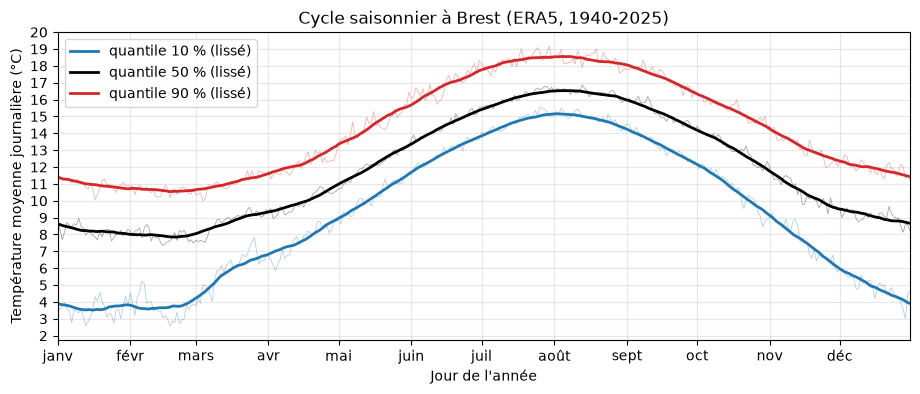

In [3]:
# on enlève les 29 février pour avoir 365 jours chaque année
d = daily_temp_brest.copy()
d['date'] = pd.to_datetime(d['valid_time'])
d = d[d['date'].dt.strftime('%m-%d') != '02-29']
d['jour'] = d.groupby(d['date'].dt.year).cumcount() + 1   # numéro du jour dans l'année (1 à 365)

# quantiles 10 %, 50 % et 90 % de la température pour chaque jour de l'année
q = pd.DataFrame({'q10': d.groupby('jour')['mean'].quantile(0.1),
                  'q50': d.groupby('jour')['mean'].quantile(0.5),
                  'q90': d.groupby('jour')['mean'].quantile(0.9)})

# moyenne glissante sur 31 jours ; comme l'année est un cycle, on colle fin décembre
# avant janvier et début janvier après décembre pour lisser aussi les bords
q_etendu = pd.concat([q.tail(15), q, q.head(15)])
qs = q_etendu.rolling(31, center=True).mean().iloc[15:-15]

# en fin : quantiles bruts ; en épais : quantiles lissés
for nom, couleur in [('q10', 'tab:blue'), ('q50', 'black'), ('q90', 'tab:red')]:
    plt.plot(q[nom], color=couleur, lw=0.6, alpha=0.35)
    plt.plot(qs[nom], color=couleur, lw=2, label=f'quantile {nom[1:]} % (lissé)')
plt.xlim(1, 365)
plt.xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
           ['janv', 'févr', 'mars', 'avr', 'mai', 'juin', 'juil', 'août', 'sept', 'oct', 'nov', 'déc'])
plt.yticks(range(2, 21))   # une graduation par °C pour lire les écarts entre courbes
plt.xlabel("Jour de l'année")
plt.ylabel('Température moyenne journalière (°C)')
plt.title('Cycle saisonnier à Brest (ERA5, 1940-2025)')
plt.legend()
plt.show()

**Commentaire.** Les trois courbes ont la même forme. La température est la plus basse vers le 19 février (quantile 50 %
à 7,8 °C) et la plus haute vers le 7 août (16,5 °C), donc environ 9 °C d'écart seulement entre l'hiver et l'été.

On pourrait s'attendre à ce que les jours les plus chauds soient autour du 21 juin, le jour où il y a le plus de soleil.
Pourtant le pic arrive vers le 7 août, environ 7 semaines plus tard, et le creux vers le 19 février au lieu du
21 décembre. On pense que c'est dû à la mer autour de Brest : elle se réchauffe et se refroidit lentement, donc l'air
suit le soleil avec du retard.

L'écart entre les quantiles 10 % et 90 % (entre la courbe bleue et la rouge) change selon la saison : environ 7,5 °C vers
le 10 janvier contre 3,4 °C fin juillet. Un même jour d'hiver peut donc être très doux ou très froid selon les années,
alors qu'en été les températures varient moins. La courbe à 90 % servira de seuil pour les vagues de chaleur.

Compute the duration and intensity of the different heat waves during the period 1940 to 2025. The duration corresponds to the number of consecutive days exceeding the 90% quantile. The intensity is defined as the mean temperature anomaly during those consecutive days.

In [4]:
DUREE_MIN = 3   # on garde les vagues d'au moins 3 jours chauds consécutifs

d = d.join(qs, on='jour')                # on ajoute à chaque jour les quantiles lissés de sa date
d['chaud'] = d['mean'] > d['q90']        # jour plus chaud que le quantile 90 % de sa date
d['anomalie'] = d['mean'] - d['q50']     # écart au quantile 50 % de sa date (°C)

# on numérote les suites de jours consécutifs : le numéro change à chaque passage chaud <-> pas chaud
d['suite'] = (d['chaud'] != d['chaud'].shift()).cumsum()

# chaque suite de jours chauds est une vague : durée = nombre de jours, intensité = anomalie moyenne
vagues = d[d['chaud']].groupby('suite').agg(debut=('date', 'first'),
                                            duree=('chaud', 'size'),
                                            intensite=('anomalie', 'mean'))
vagues = vagues[vagues['duree'] >= DUREE_MIN]
vagues['annee'] = vagues['debut'].dt.year

print(len(vagues), 'vagues de chaleur de 1940 à 2025')
print('\nLes plus longues :\n', vagues.nlargest(4, 'duree').round({'intensite': 2}).to_string(index=False))
print('\nLes plus intenses :\n', vagues.nlargest(4, 'intensite').round({'intensite': 2}).to_string(index=False))

421 vagues de chaleur de 1940 à 2025

Les plus longues :
      debut  duree  intensite  annee
1955-08-16     14       4.11   1955
1976-08-13     14       3.38   1976
1975-07-28     11       3.63   1975
1945-04-11     10       4.64   1945

Les plus intenses :
      debut  duree  intensite  annee
2022-07-16      3       7.69   2022
2000-06-16      3       6.69   2000
1976-06-25     10       6.51   1976
1940-06-03      6       6.10   1940


Un jour $d$ est **chaud** si $T_d>q_{90}(j_d)$, où $q_{90}(j)$ est le quantile 90 % lissé du jour de l'année $j$.
Une **vague de chaleur** est une suite de jours chauds consécutifs. Le sujet parle de « plusieurs jours », on a choisi
d'en garder au moins 3. Pour une vague $W$ :

$$\text{durée}=|W|\ \text{jours},\qquad \text{intensité}=\frac1{|W|}\sum_{d\in W}\big(T_d-q_{50}(j_d)\big)\ \text{en °C}.$$

L'intensité dit donc de combien de degrés la vague est, en moyenne, au-dessus de la normale de la date (le quantile 50 %).

**Commentaire.** On trouve 421 vagues en 86 ans, soit environ 5 par an. Les plus longues durent 14 jours (août 1955 et
août 1976). La plus intense est celle de **juillet 2022** : pendant 3 jours, il a fait en moyenne 7,7 °C de plus que la
normale pour cette date.

Une vague n'est pas forcément en été. Le seuil (le quantile 90 %) change avec la date : environ 11 °C en janvier et
18,5 °C en août. Par exemple, du 11 au 20 avril 1945, il a fait entre 12,6 et 17,4 °C pendant 10 jours : c'est très chaud
pour un mois d'avril, alors qu'en août ce seraient des jours plutôt frais.

Make the following scatter plot of the heat waves in Brest, with: x-axis representing duration, y-axis representing intensity, and the color representing the year of appearance. Comment on this figure.

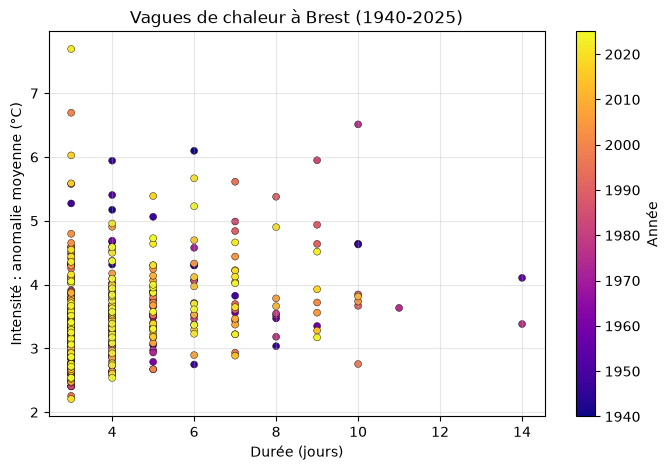

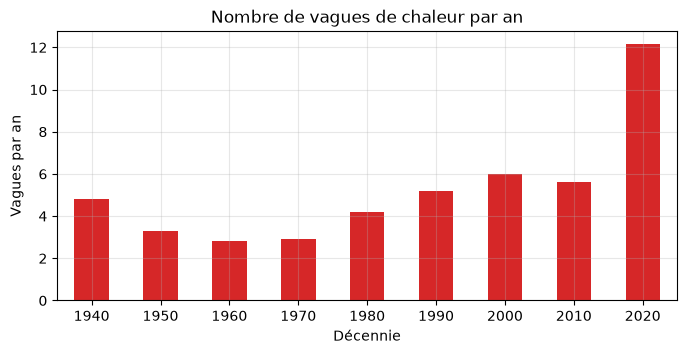

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(vagues['duree'], vagues['intensite'], c=vagues['annee'], cmap='plasma', s=25, edgecolor='k', lw=0.3)
plt.colorbar(label='Année')
plt.xlabel('Durée (jours)')
plt.ylabel('Intensité : anomalie moyenne (°C)')
plt.title('Vagues de chaleur à Brest (1940-2025)')
plt.show()

# nombre moyen de vagues par an dans chaque décennie (la décennie 2020 ne compte que 6 ans, de 2020 à 2025)
par_decennie = vagues.groupby(vagues['annee'] // 10 * 10).size()
nb_annees = pd.Series(10, index=par_decennie.index)
nb_annees[2020] = 6
(par_decennie / nb_annees).plot.bar(rot=0, color='tab:red', figsize=(8, 3.5))
plt.xlabel('Décennie')
plt.ylabel('Vagues par an')
plt.title('Nombre de vagues de chaleur par an')
plt.show()

**Commentaire.** La plupart des vagues sont courtes : environ 8 sur 10 durent 3 à 5 jours, et presque toutes ont une
intensité entre 2,5 et 5 °C. Le lien entre durée et intensité est faible : une vague longue n'est pas forcément plus
intense. Les vagues les plus intenses (plus de 5 °C) sont réparties sur toute la période, on ne voit pas de tendance
nette sur l'intensité.

Ce qui change vraiment, c'est le nombre de vagues (deuxième graphique) : environ 3 par an dans les années 1960-1970,
6 dans les années 2000, et 12 par an sur 2020-2025. Le seuil de 90 % est le même pour toutes les années, donc s'il y a
plus de vagues aujourd'hui, c'est que les températures ont augmenté.

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

In [6]:
# read data
yearly_temp_brest = pd.read_csv('yearly_temp_brest.csv')
print(yearly_temp_brest)

    valid_time        max       min         co2
0   1940-01-01  24.790497 -3.994019  310.000000
1   1941-01-01  24.934845 -1.216583  311.162500
2   1942-01-01  25.541260 -1.027679  312.329359
3   1943-01-01  27.316742  1.669037  313.500594
4   1944-01-01  25.795715 -0.246552  314.676222
..         ...        ...       ...         ...
81  2021-01-01  28.604187 -1.346619  419.789832
82  2022-01-01  34.178619  1.063812  421.364044
83  2023-01-01  27.587494  0.408691  422.944159
84  2024-01-01  29.494080 -0.848175  424.530200
85  2025-01-01  27.788269  1.253174  428.501735

[86 rows x 4 columns]


Plot and comment on the maximum annual temperature in Brest from 1940 to 2025.

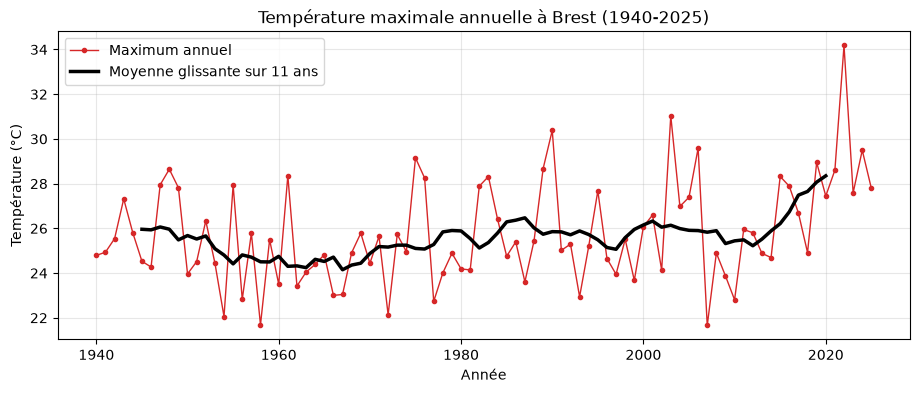

Moyenne 1940-1979 : 25.1 °C
Moyenne 1980-2025 : 26.3 °C


In [7]:
y = yearly_temp_brest.copy()
y['annee'] = pd.to_datetime(y['valid_time']).dt.year

plt.plot(y['annee'], y['max'], 'o-', ms=3, lw=1, color='tab:red', label='Maximum annuel')
# moyenne glissante sur 11 ans pour voir la tendance sans les variations d'une année à l'autre
plt.plot(y['annee'], y['max'].rolling(11, center=True).mean(), lw=2.5, color='k', label='Moyenne glissante sur 11 ans')
plt.xlabel('Année')
plt.ylabel('Température (°C)')
plt.title('Température maximale annuelle à Brest (1940-2025)')
plt.legend()
plt.show()

print('Moyenne 1940-1979 :', round(y.loc[y['annee'] < 1980, 'max'].mean(), 1), '°C')
print('Moyenne 1980-2025 :', round(y.loc[y['annee'] >= 1980, 'max'].mean(), 1), '°C')

**Commentaire.** Le maximum annuel varie beaucoup d'une année à l'autre : de 21,7 °C (1958 et 2007) à 34,2 °C (2022).
C'est normal, car il ne dépend que des quelques jours les plus chauds de l'année.

La moyenne sur 11 ans montre mieux la tendance. Elle baisse un peu entre les années 1940 et 1960 (de 26 à environ
24,5 °C), remonte vers 26 °C dans les années 1980, reste à peu près stable jusqu'en 2010, puis monte nettement jusqu'à
environ 28,4 °C autour de 2020. En moyenne, le maximum annuel vaut 25,1 °C sur 1940-1979 et 26,3 °C sur 1980-2025.
Le record de 2022 (34,2 °C) dépasse de plus de 3 °C le deuxième plus chaud (31,0 °C en 2003).

Compute the correlation between the maximum annual temperature in Brest and the global annual CO2. To increase the linear correlation coefficient, test several transformations of those two variables.

In [8]:
# transformations testées pour la température et pour le CO2
T = {'T': y['max'],
     'ln(T)': np.log(y['max']),
     'T lissée 5 ans': y['max'].rolling(5, center=True).mean(),
     'T lissée 11 ans': y['max'].rolling(11, center=True).mean(),
     'T lissée 21 ans': y['max'].rolling(21, center=True).mean()}
CO2 = {'CO2': y['co2'], 'ln(CO2)': np.log(y['co2']), 'CO2²': y['co2']**2}

# coefficient de corrélation linéaire pour chaque couple (température, CO2)
tableau = pd.DataFrame({c: {t: T[t].corr(CO2[c]) for t in T} for c in CO2})
print('Corrélation linéaire entre Tmax et CO2 (1940-2025) :')
print(tableau.round(2))

Corrélation linéaire entre Tmax et CO2 (1940-2025) :
                  CO2  ln(CO2)  CO2²
T                0.31     0.30  0.32
ln(T)            0.31     0.30  0.32
T lissée 5 ans   0.49     0.47  0.51
T lissée 11 ans  0.61     0.60  0.62
T lissée 21 ans  0.83     0.82  0.83


**Commentaire.** La corrélation entre Tmax et le CO2 est faible ($r = 0{,}31$) : d'une année à l'autre, Tmax varie
beaucoup, et le CO2 n'explique qu'une petite partie de ces variations.

Transformer les variables (ln, carré) ne change presque rien (entre 0,30 et 0,32). C'est logique : sur des intervalles
aussi petits (310 à 428 ppm, 21 à 34 °C), ces fonctions sont presque des droites.

Par contre, lisser la température augmente beaucoup la corrélation : 0,49 sur 5 ans, 0,61 sur 11 ans, 0,83 sur 21 ans.
La tendance de Tmax suit donc bien le CO2, mais pas la valeur d'une année précise. C'est pour ça qu'il faut des
prédictions probabilistes, et pas une seule valeur par année.

Use recent machine learning methods to provide probabilistic predictions (not deterministic) of maximum annual temperatures until 2100, conditionally on the three main climate scenarios. These SSPs differ in their level of annual CO2 emissions. Do not forget to present your approach mathematically and to justify your choice.

In [9]:
# read data
yearly_future_co2 = pd.read_csv('yearly_future_co2.csv')
print(yearly_future_co2)

    valid_time    ssp1-2.6    ssp2-4.5    ssp5-8.5
0   2026-01-01  420.780225  420.188542  421.121677
1   2027-01-01  421.558613  423.729506  425.754016
2   2028-01-01  422.333331  427.165818  430.437310
3   2029-01-01  423.102552  430.500572  435.172120
4   2030-01-01  423.864459  433.736770  439.959014
..         ...         ...         ...         ...
70  2096-01-01  405.235885  525.328317  905.708594
71  2097-01-01  403.933331  525.761931  915.671389
72  2098-01-01  402.625279  526.182729  925.743774
73  2099-01-01  401.313558  526.591091  935.926955
74  2100-01-01  400.000000  526.987384  946.222152

[75 rows x 4 columns]


## Notre démarche

Pour cette partie, nous avons organisé une petite compétition au sein du groupe : chaque membre a proposé et codé sa
propre méthode de prédiction probabiliste, puis toutes les méthodes ont été évaluées selon le même protocole. Seule la
meilleure selon ce protocole est présentée en détail dans la suite ; les autres sont résumées ci-dessous avec leur
score.

Le protocole est le suivant :

- entraînement sur les années **1940-2000** uniquement ;
- prédiction de chaque année **2001-2025** à partir de son CO2 (10 000 tirages par année) ;
- comparaison avec les températures observées à l'aide du **score CRPS** (défini plus bas).

Les années 2001-2025 ont des concentrations de CO2 plus élevées que toutes celles de l'entraînement. Ce test reproduit
donc, à petite échelle, la difficulté de 2100 : prédire pour un CO2 jamais observé.

### Les méthodes proposées

- **Référence** (point de comparaison) : une droite en fonction de $\ln(\mathrm{CO_2})$, plus un bruit gaussien.
- **Régression bayésienne** (Christian) : la même droite, mais au lieu d'une seule pente, on tire des milliers de
  pentes possibles. La prédiction devient donc plus incertaine quand on s'éloigne des données.
- **Loi des valeurs extrêmes, GEV** (Reda) : la loi que donne la théorie pour le maximum d'un grand nombre de valeurs
  (ici, le maximum de toutes les températures de l'année). Le centre de la loi dépend du CO2. Pour Tmin, on applique la même
  méthode à $-T_{\min}$, car le minimum est le maximum des valeurs opposées.
- **Modèles de diffusion** (Elias) : le type de réseau suggéré par le sujet. Une droite en $\ln(\mathrm{CO_2})$ sert
  d'« ancre », et un réseau de neurones génère les écarts à cette droite par diffusion : il part d'un bruit pur et le
  « débruite » pour obtenir un tirage. Elias a testé plusieurs versions : un DDPM classique (abandonné, car il
  produisait des valeurs absurdes pour Tmin, jusqu'à −1 933 °C), une diffusion entraînée au CRPS, et la même avec une
  ancre incertaine (la droite elle-même est tirée au hasard).
- **Régression quantile** (Yazid) : au lieu de supposer une loi, on ajuste 99 droites, une par quantile (1 %, 2 %, …,
  99 %).
- **Réseau à mélange de gaussiennes** (Diae) : un réseau de neurones qui donne, pour chaque valeur du CO2, un mélange
  de 3 lois normales (leurs poids, moyennes et écarts-types).

### Le score : le CRPS

Nos méthodes ne donnent pas une valeur mais une loi, donc l'erreur habituelle $|\text{prédiction} - \text{observation}|$
ne suffit pas. Le CRPS compare toute la loi prédite $F$ à la valeur observée $y$ :
$$\mathrm{CRPS}(F,y)=\mathbb E|X-y|-\tfrac12\,\mathbb E|X-X'|$$
où $X$ et $X'$ sont deux tirages faits au hasard dans notre loi prédite, l'un indépendamment de l'autre.

- Le premier terme est la distance moyenne entre nos tirages et la réalité : il est petit si la loi est bien centrée.
- Le second terme mesure la largeur de notre loi. Sans lui, le meilleur choix serait de toujours prédire une seule
  valeur ; avec lui, une loi qui a la bonne largeur est récompensée.

On calcule le CRPS pour chacune des 25 années de 2001-2025, puis on fait la moyenne : c'est ce score moyen qui
figure dans le tableau. Il est en °C et plus il est petit, mieux c'est. Pour une prédiction à une seule valeur, il
redonne l'erreur absolue.

### Résultats sur 2001-2025

| Méthode | Proposée par | CRPS Tmax (°C) | CRPS Tmin (°C) |
|:--|:--|:-:|:-:|
| **Régression bayésienne** | Christian | **1,57** | **0,98** |
| Diffusion avec ancre incertaine | Elias | 1,65 | 0,99 |
| Loi des valeurs extrêmes (GEV) | Reda | 1,68 | 0,99 |
| Référence | — | 1,70 | 1,14 |
| Diffusion entraînée au CRPS | Elias | 1,70 | 1,03 |
| Régression quantile | Yazid | 1,81 | 1,07 |
| Réseau à mélange de gaussiennes | Diae | 1,85 | 1,18 |

Les réseaux de neurones et la GEV ont été codés en PyTorch, et les modèles d'Elias entraînés sur GPU. Les scores
varient d'environ ±0,03 °C d'une exécution à l'autre.

La régression bayésienne a le meilleur CRPS pour Tmax. Pour Tmin, elle est à égalité avec la GEV et la diffusion
(0,98 à 0,99). Les réseaux de neurones ne font pas mieux, pour une raison simple : ils ont beaucoup de paramètres à
régler (environ 1 200 pour la diffusion) et seulement 61 années pour apprendre. Avec si peu de données, ils ne peuvent
pas apprendre mieux qu'une loi simple. D'ailleurs, la meilleure diffusion est celle où la droite est incertaine :
c'est la même idée que la régression bayésienne.

Attention, « meilleur » veut dire ici meilleur CRPS sur 2001-2025, pas meilleur modèle dans l'absolu : 25 années de
test, c'est peu, et le CRPS dit peu de chose sur les valeurs extrêmes. C'est le critère qui nous paraît le plus
raisonnable, mais d'autres choix restaient défendables (par exemple la GEV, faite pour les extrêmes).

**Ce que donnent les méthodes en 2100.** On a aussi regardé ce que chaque méthode prédit pour Tmax en 2100 avec
SSP5-8.5 (946 ppm), une fois réentraînée sur 1940-2025 :

| Méthode | Médiane (°C) | Intervalle 5-95 % (°C) | P(Tmax 2100 > 40 °C) | Problème |
|:--|:-:|:-:|:-:|:--|
| **Régression bayésienne** | 32,8 | 27,4 – 38,2 | 1,5 % | — |
| Diffusion avec ancre incertaine (Elias) | 32,5 | 26,7 – 39,0 | 3,0 % | — |
| Diffusion entraînée au CRPS (Elias) | 32,6 | 28,7 – 37,3 | 0,6 % | — |
| GEV (Reda) | 31,4 | 26,2 – 37,1 | 0,8 % | — |
| Référence | 32,8 | 29,2 – 36,4 | 0,01 % | trop sûre d'elle |
| Régression quantile (Yazid) | 31,7 | 26,6 – 44,0 | 6,8 % | diverge |
| Réseau à mélange (Diae) | 29,1 | 23,8 – 34,7 | 0,06 % | ne suit plus le CO2 |

La diffusion et la GEV donnent des résultats proches des nôtres. Trois méthodes posent problème :

- la régression quantile diverge : ses 99 droites s'écartent quand on s'éloigne des données ;
- le réseau de Diae n'a jamais vu un CO2 aussi élevé, et sa prédiction reste bloquée vers 29 °C dès 2050 ;
- la référence est trop sûre d'elle : avec une seule droite, elle donne 0,01 % au lieu de 1,5 %.

Notre choix est donc cohérent avec ce que les méthodes prédisent pour 2100, et pas seulement avec le CRPS.

**Dans la suite**, on développe les deux premières méthodes du tableau des scores : la régression bayésienne, qu'on
retient pour les projections, et la diffusion, le type de modèle suggéré par le sujet. La méthode retenue est
**réentraînée sur toutes les années 1940-2025** pour prédire jusqu'en 2100 : le test sur 2001-2025 servait seulement à
choisir, et il vaut mieux utiliser toutes les données pour prédire le futur.

## Le modèle retenu : régression bayésienne

**Notations.** $T_t$ est le Tmax de l'année $t$ (°C), $x_t=\ln(C_t)$ où $C_t$ est le CO2 de l'année (ppm), et
$T=(T_{1940},\dots,T_{2025})$ la liste des $n=86$ valeurs observées. Le signe « $\mid$ » se lit « sachant » et
« $\sim$ » se lit « suit la loi ».

**Le modèle.** Tmax est une droite en $\ln(\mathrm{CO_2})$ plus un bruit, qui représente la météo de l'année :
$$T_t=a+b\,x_t+\sigma\,\varepsilon_t,\qquad \varepsilon_t\sim\mathcal N(0,1)\ \text{indépendants}.$$
$a$ est la hauteur de la droite, $b$ sa pente, et $\sigma$ l'écart-type du bruit (de combien une année s'écarte en
général de la droite).

**Pourquoi $\ln(\mathrm{CO_2})$ ?** À la question précédente, CO2, $\ln(\mathrm{CO_2})$ et CO2² avaient la même corrélation
(0,30 à 0,32). Mais en 2100 avec SSP5-8.5 (946 ppm), une simple droite donne un Tmax moyen d'environ 33 °C avec
$\ln(\mathrm{CO_2})$, 38 °C avec CO2 et 48 °C avec CO2². On garde $\ln(\mathrm{CO_2})$ : l'effet du CO2 sur la température
est connu pour être logarithmique (chaque doublement du CO2 réchauffe d'à peu près la même quantité), et c'est le seul
choix qui reste réaliste en 2100.

**Pourquoi bayésien ?** Avec 86 années, on ne connaît pas $a$, $b$ et $\sigma$ exactement : la pente estimée vaut
environ $7{,}4 \pm 2{,}5$. Sur les CO2 observés, ça change peu de chose, mais à 946 ppm une petite erreur sur la pente
devient une grosse erreur sur la température. Au lieu de garder une seule droite (celle des moindres carrés), on met
une **loi de probabilité sur les paramètres**, qui dit quelles valeurs de $(a,b,\sigma)$ sont plausibles, et on en
tire **beaucoup**. On part d'un a priori non informatif, avec une seule contrainte : plus de CO2 ne refroidit pas.
$$p(a,b,\sigma^2)\propto\sigma^{-2}\,\mathbf 1_{b\ge0}.$$

**La loi a posteriori** (ce qu'on sait des paramètres après avoir vu les données). On note $X$ le tableau des données
(une colonne de 1 et une colonne $x_t$), $\hat\beta=(\hat a,\hat b)=(X^\top X)^{-1}X^\top T$ la droite des moindres carrés,
et $\mathrm{MSE}=\frac1n\sum_t(T_t-\hat a-\hat b\,x_t)^2$ l'erreur quadratique moyenne de cette droite. Pour ce modèle,
le résultat est classique :
$$\sigma^2\mid T\sim\frac{n\cdot\mathrm{MSE}}{\chi^2_{n-2}},\qquad (a,b)\mid\sigma^2,T\sim\mathcal N\big(\hat\beta,\ \sigma^2(X^\top X)^{-1}\big).$$
Le $\chi^2_{n-2}$ vient du fait que la somme des carrés des écarts, divisée par $\sigma^2$, est une somme de carrés de
lois normales ($n-2$ car on a estimé deux paramètres, $a$ et $b$). Pour tirer $(a,b,\sigma)$ ensemble, on tire d'abord
$\sigma^2$, puis $(a,b)$ sachant ce $\sigma^2$ : c'est la règle $p(a,b,\sigma^2)=p(\sigma^2)\,p(a,b\mid\sigma^2)$. Enfin,
on rejette les tirages où $b<0$.

**Prédiction par Monte-Carlo.** Pour une année future de CO2 $C$, on tire $N=10\,000$ jeux $(a^{(k)},b^{(k)},\sigma^{(k)})$
et, pour chacun, **une** température :
$$T^{(k)}=a^{(k)}+b^{(k)}\ln C+\sigma^{(k)}z^{(k)},\qquad z^{(k)}\sim\mathcal N(0,1).$$
Exemple avec trois vrais tirages pour 2100 et SSP5-8.5 ($\ln C = 6{,}85$) :

| $k$ | $\sigma$ | $a$ | $b$ | droite en 2100 | bruit $z$ | Tmax 2100 |
|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| 1 | 1,89 | −12,5 | 6,47 | 31,8 °C | −0,45 | 31,0 °C |
| 2 | 2,23 | −21,4 | 7,97 | 33,2 °C | +3,32 | 40,6 °C |
| 3 | 2,16 | −22,1 | 8,08 | 33,3 °C | −1,06 | 31,1 °C |

Les 10 000 valeurs de la dernière colonne forment la loi de Tmax en 2100, et $P(\text{Tmax}>40\,°\text{C})$ est la part
de tirages au-dessus de 40 °C. La loi contient deux hasards : la météo de l'année ($\sigma z$), et notre incertitude sur
la droite, qui change à chaque tirage grâce au bayésien. Sans le bayésien, la droite en 2100 vaudrait toujours
32,8 °C, la loi serait plus étroite et la probabilité de dépasser 40 °C tomberait d'environ 1,6 % à 0,05 %.

In [10]:
N = 10_000                          # nombre de tirages Monte-Carlo par année
x = np.log(y['co2'].to_numpy())     # variable explicative : ln(CO2)

def ajuster(x, t):
    # tout ce qu'il faut pour tirer dans la loi a posteriori de (a, b, sigma)
    X = np.c_[np.ones_like(x), x]
    V = np.linalg.inv(X.T @ X)
    beta = V @ X.T @ t                       # moindres carrés
    mse = np.mean((t - X @ beta) ** 2)        # erreur quadratique moyenne de la droite
    return beta, V, mse, len(t)

def tirer(modele, x_futur, n=N):
    # n tirages de la température pour chaque valeur de x_futur : tableau (n, nombre d'années)
    beta, V, mse, n_annees = modele
    params = np.empty((0, 3))
    while len(params) < n:                   # on tire jusqu'à avoir n jeux de paramètres avec b >= 0
        s = np.sqrt(n_annees * mse / rng.chisquare(n_annees - 2, n))      # sigma (loi du chi2)
        ab = beta + s[:, None] * rng.standard_normal((n, 2)) @ np.linalg.cholesky(V).T   # (a, b) sachant sigma
        garder = ab[:, 1] >= 0               # rejet : plus de CO2 ne refroidit pas
        params = np.vstack([params, np.c_[ab[garder], s[garder]]])
    a, b, s = params[:n].T
    return a[:, None] + b[:, None] * x_futur + s[:, None] * rng.standard_normal((n, len(x_futur)))

def crps(tirages, obs):
    # CRPS moyen (°C) entre les tirages (n, nombre d'années) et les valeurs observées
    s = np.sort(tirages, axis=0)
    n = len(s)
    w = (2 * np.arange(1, n + 1) - n - 1) / n**2
    return np.mean(np.abs(s - obs).mean(axis=0) - w @ s)

In [11]:
# on refait le test du groupe : appris sur 1940-2000, noté sur 2001-2025
avant, apres = (y['annee'] <= 2000).to_numpy(), (y['annee'] > 2000).to_numpy()
for var in ['max', 'min']:
    m = ajuster(x[avant], y[var].to_numpy()[avant])
    print(f'CRPS T{var} 2001-2025 : {crps(tirer(m, x[apres]), y[var].to_numpy()[apres]):.2f} °C')

CRPS Tmax 2001-2025 : 1.57 °C
CRPS Tmin 2001-2025 : 0.98 °C


**Commentaire.** On retrouve les scores du tableau : 1,57 °C pour Tmax et 0,98 °C pour Tmin, contre 1,70 et 1,14 °C
pour le modèle de référence.

## Le modèle de diffusion (Elias)

C'est le type de réseau suggéré par le sujet. L'idée, en trois points :

- on garde une droite en $\ln(\mathrm{CO_2})$, l'« ancre », et on regarde les écarts des années à cette droite ;
- un réseau de neurones apprend à fabriquer des écarts réalistes : on abîme un vrai écart avec du bruit, le réseau
  doit retrouver un écart propre, et on note ses propositions avec le CRPS ;
- pour prédire, on lui donne un bruit pur, il en fait un écart, et on l'ajoute à une droite tirée au hasard parmi 500
  droites plausibles (l'« ancre incertaine »).

En formules : avec $z=(T-a-b\ln C)/e$ l'écart réduit à la droite, on abîme $z$ en $u=(1-s)\,z+s\,\varepsilon$, avec un
niveau de bruit $s\sim\mathcal U(0,1)$ et $\varepsilon\sim\mathcal N(0,1)$. Le réseau $g_\phi$ propose $M=32$ écarts
$\hat z_m=g_\phi(u,s,\zeta_m)$, avec $\zeta_m\sim\mathcal N(0,1)$, et on minimise le CRPS de ces propositions face à $z$.
Pour prédire, on prend $s=1$ et $u\sim\mathcal N(0,1)$, puis $T=a^{(k)}+b^{(k)}\ln C+e\,\hat z$.

In [12]:
alea = np.random.default_rng(1)       # générateur à part, pour ne pas changer les tirages de la suite

def ancre(x, t):
    # droite en ln(CO2), avec pente >= 0 (plus de CO2 ne refroidit pas)
    b = max(np.polyfit(x, t, 1)[0], 0.0)
    return np.mean(t - b * x), b

class Debruiteur(torch.nn.Module):
    # g(u, s, zeta) : reçoit un écart abîmé u, le niveau de bruit s et un hasard zeta, et propose un écart propre
    def __init__(self):
        super().__init__()
        self.reseau = torch.nn.Sequential(torch.nn.Linear(3, 32), torch.nn.SiLU(),
                                          torch.nn.Linear(32, 32), torch.nn.SiLU(), torch.nn.Linear(32, 1))
    def forward(self, u, s, zeta):
        return self.reseau(torch.stack([u, s, zeta], dim=-1)).squeeze(-1)

def crps_entrainement(X, y, alpha=0.95):
    # CRPS de M propositions X (lot, M) face à y (lot) : 95 % version sans biais + 5 % version empirique
    M = X.shape[1]
    X = X.sort(dim=1).values
    w = 2 * torch.arange(1, M + 1) - M - 1
    return ((X - y[:, None]).abs().mean(1) - (X * w).sum(1) * (alpha / (M * (M - 1)) + (1 - alpha) / M**2)).mean()

def entrainer_diffusion(x, t, pas, M=32, B=500):
    a, b = ancre(x, t)
    r = t - a - b * x
    e = np.std(r, ddof=2)
    z = torch.tensor(r / e, dtype=torch.float32)                 # écarts réduits à la droite
    torch.manual_seed(0)
    g = Debruiteur()
    opt = torch.optim.AdamW(g.parameters(), lr=1e-3, weight_decay=1e-4)
    for _ in range(pas):
        zb = z[torch.randint(len(z), (64,))]
        s = torch.rand(64)                                       # niveau de bruit entre 0 et 1
        u = (1 - s) * zb + s * torch.randn(64)                   # écart abîmé par le bruit
        X = g(u[:, None].expand(-1, M), s[:, None].expand(-1, M), torch.randn(64, M))   # M propositions
        opt.zero_grad()
        crps_entrainement(X, zb).backward()
        torch.nn.utils.clip_grad_norm_(g.parameters(), 1.0)
        opt.step()
    # ancre incertaine : B droites réajustées après avoir rééchantillonné les écarts par blocs de 3 années
    n, rc = len(r), r - r.mean()
    droites = []
    for _ in range(B):
        debuts = alea.integers(0, n, size=-(-n // 3))
        ix = ((debuts[:, None] + np.arange(3)) % n).ravel()[:n]
        droites.append(ancre(x, a + b * x + rc[ix]))
    return g, e, np.array(droites)

def tirer_diffusion(modele, x_futur, n=N):
    g, e, droites = modele
    with torch.no_grad():                                        # prédiction : bruit pur (s = 1), un passage
        forme = (n, len(x_futur))
        z = g(torch.randn(forme), torch.ones(forme), torch.randn(forme)).numpy()
    a, b = droites[alea.integers(len(droites), size=n)].T
    return a[:, None] + b[:, None] * x_futur + e * z

PAS = {'max': 1250, 'min': 1500}      # nombres de pas retenus par Elias

# même test que pour la régression bayésienne : appris sur 1940-2000, noté sur 2001-2025
for var in ['max', 'min']:
    m = entrainer_diffusion(x[avant], y[var].to_numpy()[avant], PAS[var])
    print(f'Diffusion, CRPS T{var} 2001-2025 : {crps(tirer_diffusion(m, x[apres]), y[var].to_numpy()[apres]):.2f} °C')

# Tmax en 2100 avec SSP5-8.5, après réentraînement sur 1940-2025
# modèle réentraîné sur 1940-2025, utilisé à la question suivante pour les projections
diffusion_max = entrainer_diffusion(x, y['max'].to_numpy(), PAS['max'])

Diffusion, CRPS Tmax 2001-2025 : 1.65 °C


Diffusion, CRPS Tmin 2001-2025 : 0.99 °C


**Commentaire.** On retrouve les scores d'Elias : 1,65 °C pour Tmax et 0,99 °C pour Tmin. La diffusion fait mieux que
la référence, mais pas mieux que la régression bayésienne (1,57 et 0,98 °C).

La raison est simple : il n'y a pas assez de données. Le réseau a 1 217 paramètres à régler, et seulement 61 années
pour apprendre. Avec si peu d'exemples, il ne peut pas apprendre la forme des écarts à la droite mieux qu'une simple
loi normale. Ce qui l'aide vraiment, c'est l'ancre incertaine, c'est-à-dire la même idée que la régression bayésienne.

En 2100 avec SSP5-8.5, la diffusion donne une médiane de 32,7 °C et une probabilité de dépasser 40 °C de 2,9 %,
proches de nos résultats. On garde donc la régression bayésienne pour les projections : elle fait aussi bien, en plus
simple.

## Projections jusqu'en 2100 avec la régression bayésienne

On revient à la méthode retenue. La régression bayésienne est réentraînée sur toutes les années 1940-2025, puis on
tire 10 000 températures pour chaque année de 2026 à 2100 et chaque scénario. Le graphique montre la médiane (trait)
et l'intervalle 5-95 % (bande) des tirages.

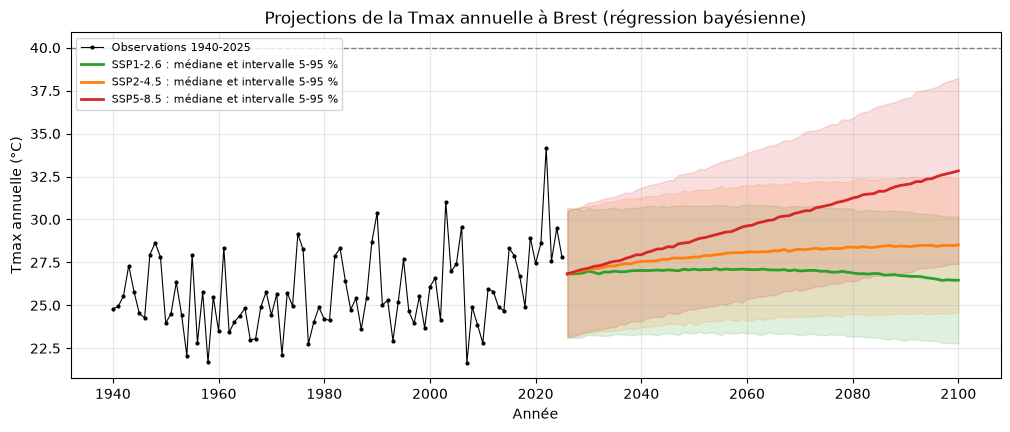

In [13]:
futur = yearly_future_co2.copy()
futur['annee'] = pd.to_datetime(futur['valid_time']).dt.year
SSP = {'ssp1-2.6': 'tab:green', 'ssp2-4.5': 'tab:orange', 'ssp5-8.5': 'tab:red'}

def projeter(var):
    # modèle réajusté sur 1940-2025, puis 10 000 tirages pour chaque année 2026-2100 et chaque scénario
    m = ajuster(x, y[var].to_numpy())
    return {s: tirer(m, np.log(futur[s].to_numpy())) for s in SSP}

def tracer(var, sims, seuil):
    plt.figure(figsize=(12, 4.5))
    plt.plot(y['annee'], y[var], 'k.-', lw=0.8, ms=4, label='Observations 1940-2025')
    for s, couleur in SSP.items():
        q5, q50, q95 = np.percentile(sims[s], [5, 50, 95], axis=0)
        plt.fill_between(futur['annee'], q5, q95, color=couleur, alpha=0.15)
        plt.plot(futur['annee'], q50, color=couleur, lw=2, label=f'{s.upper()} : médiane et intervalle 5-95 %')
    plt.axhline(seuil, color='grey', ls='--', lw=1)
    plt.xlabel('Année')
    plt.ylabel(f'T{var} annuelle (°C)')
    plt.title(f'Projections de la T{var} annuelle à Brest (régression bayésienne)')
    plt.legend(loc='upper left', fontsize=8)
    plt.show()

sims_max = projeter('max')
tracer('max', sims_max, 40)

**Commentaire.** Les trois scénarios partent du même niveau en 2026 (médiane d'environ 27 °C) puis s'écartent. Avec
SSP1-2.6, le CO2 redescend à 400 ppm et la médiane reste à 26,5 °C en 2100. Avec SSP2-4.5, elle atteint 28,5 °C, et avec
SSP5-8.5 (946 ppm) 32,8 °C : une année normale de 2100 serait alors aussi chaude que les années les plus chaudes
observées jusqu'ici. Les bandes 5-95 % sont larges (environ 7 °C en 2026, 11 °C en 2100 pour SSP5-8.5) : Tmax varie
beaucoup d'une année à l'autre, et l'incertitude sur la pente compte de plus en plus quand le CO2 augmente.

Based on your probabilistic predictions, provide the distribution of the maximum annual temperature in 2100 for the three climate scenarios (SSPs). Based on your predictions, what is the probability of exceeding 40°C in Brest, by 2100, for the three climate scenarios?

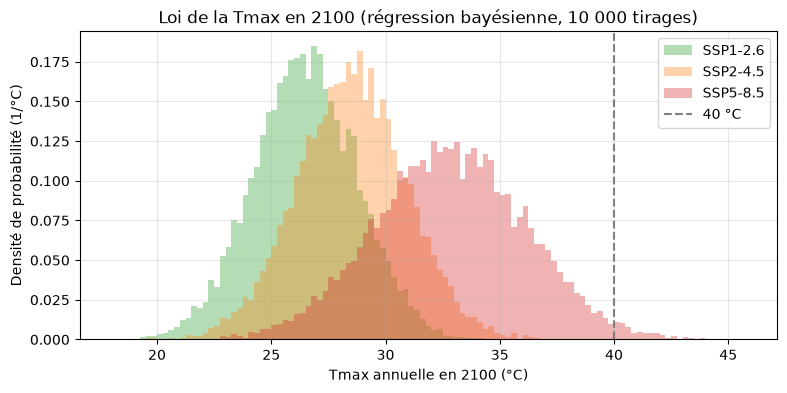

Régression bayésienne :
          CO2 2100 (ppm)  q5 2100 (°C)  q50 2100 (°C)  q95 2100 (°C)  P(T 2100 > 40 °C)  P(au moins une fois 2026-2100)
SSP1-2.6        400.0000       22.8037        26.4605        30.1723             0.0000                          0.0000
SSP2-4.5        526.9874       24.5908        28.5249        32.3971             0.0000                          0.0000
SSP5-8.5        946.2222       27.4077        32.8329        38.2422             0.0154                          0.0784

Diffusion :
          CO2 2100 (ppm)  q5 2100 (°C)  q50 2100 (°C)  q95 2100 (°C)  P(T 2100 > 40 °C)  P(au moins une fois 2026-2100)
SSP1-2.6        400.0000       22.1326        26.1711        30.8097             0.0000                          0.0000
SSP2-4.5        526.9874       23.8998        28.3321        33.2256             0.0001                          0.0013
SSP5-8.5        946.2222       26.8010        32.7480        38.9011             0.0288                          0.1711


In [14]:
def resume_2100(sims, seuil, au_dessus=True):
    lignes = {}
    for s, t in sims.items():
        depasse = t > seuil if au_dessus else t < seuil
        lignes[s.upper()] = {'CO2 2100 (ppm)': futur[s].iloc[-1],
                             **{f'q{p} 2100 (°C)': np.percentile(t[:, -1], p) for p in (5, 50, 95)},
                             f'P(T 2100 {">" if au_dessus else "<"} {seuil} °C)': depasse[:, -1].mean(),
                             'P(au moins une fois 2026-2100)': depasse.any(axis=1).mean()}
    return pd.DataFrame(lignes).T

plt.figure(figsize=(9, 4))
for s, couleur in SSP.items():
    plt.hist(sims_max[s][:, -1], np.arange(18, 46, 0.25), density=True, histtype='stepfilled', alpha=0.35,
             color=couleur, label=s.upper())
plt.axvline(40, color='grey', ls='--', label='40 °C')
plt.xlabel('Tmax annuelle en 2100 (°C)')
plt.ylabel('Densité de probabilité (1/°C)')
plt.title('Loi de la Tmax en 2100 (régression bayésienne, 10 000 tirages)')
plt.legend()
plt.show()
print('Régression bayésienne :')
print(resume_2100(sims_max, 40).round(4).to_string())

# même calcul avec la diffusion, pour comparer
sims_diffusion = {s: tirer_diffusion(diffusion_max, np.log(futur[s].to_numpy())) for s in SSP}
print('\nDiffusion :')
print(resume_2100(sims_diffusion, 40).round(4).to_string())

<div style="border: 3px solid #c0392b; border-radius: 8px; padding: 10px 16px; margin: 8px 0;">

**Réponse : probabilité de dépasser 40 °C à Brest (régression bayésienne)**

| Scénario | Médiane de Tmax en 2100 | P(Tmax 2100 > 40 °C) | P(au moins une année > 40 °C entre 2026 et 2100) |
|:--|:-:|:-:|:-:|
| SSP1-2.6 | 26,5 °C | ≈ 0 | ≈ 0 |
| SSP2-4.5 | 28,5 °C | ≈ 0 | ≈ 0 |
| SSP5-8.5 | 32,8 °C | **1,5 %** | **7,8 %** |

</div>

**Commentaire.** Dépasser 40 °C reste rare pour une année donnée, même en 2100 avec SSP5-8.5 (1,5 %). Sur 75 ans, le
risque s'accumule : dans ce scénario, environ 1 trajectoire sur 13 dépasse 40 °C au moins une fois. Avec 10 000
tirages, « 0 » veut seulement dire moins d'environ 1 chance sur 10 000, pas que c'est impossible.

La diffusion donne des médianes très proches (26,2 / 28,3 / 32,7 °C), mais une queue un peu plus longue du côté chaud :
2,9 % en 2100 et 17 % au moins une fois d'ici 2100 avec SSP5-8.5. L'ordre de grandeur est le même : quelques pour cent
pour une année, et de l'ordre de 10 % sur 75 ans dans le pire scénario.

Il faut prendre ces chiffres avec prudence : 40 °C est loin de tout ce qu'on a observé (34,2 °C au maximum), et on
extrapole jusqu'à 946 ppm alors qu'on n'a vu que 310 à 428 ppm. Le CO2 est aussi la seule entrée du modèle.

Make the same study for the minimum annual temperatures in Brest. You can try a different approach to generate your predictions (without including the mathematical formulation).

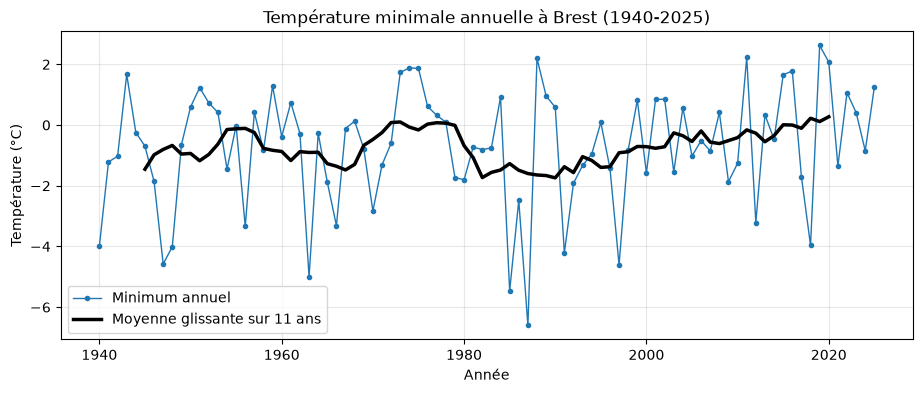

Corrélation Tmin / ln(CO2) : 0.15


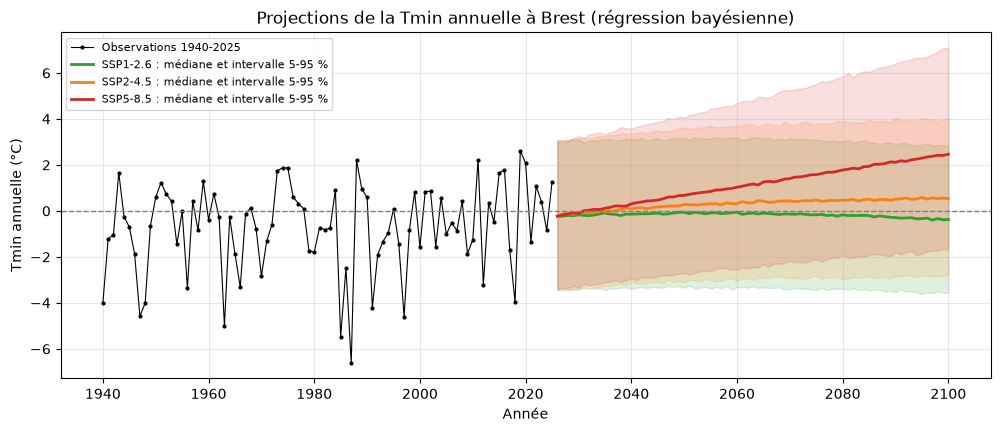

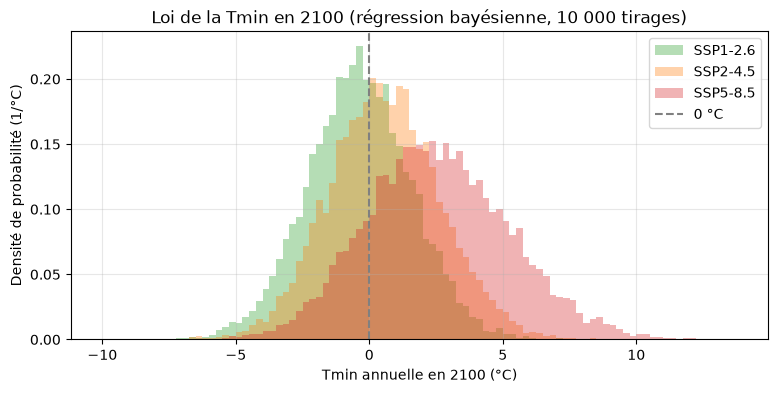

          CO2 2100 (ppm)  q5 2100 (°C)  q50 2100 (°C)  q95 2100 (°C)  P(T 2100 < 0 °C)  P(au moins une fois 2026-2100)
SSP1-2.6         400.000        -3.551         -0.378          2.830             0.578                             1.0
SSP2-4.5         526.987        -2.756          0.538          4.039             0.394                             1.0
SSP5-8.5         946.222        -1.659          2.468          7.096             0.168                             1.0


In [15]:
# même étude que pour Tmax : d'abord les observations 1940-2025
plt.plot(y['annee'], y['min'], 'o-', ms=3, lw=1, color='tab:blue', label='Minimum annuel')
plt.plot(y['annee'], y['min'].rolling(11, center=True).mean(), lw=2.5, color='k', label='Moyenne glissante sur 11 ans')
plt.xlabel('Année')
plt.ylabel('Température (°C)')
plt.title('Température minimale annuelle à Brest (1940-2025)')
plt.legend()
plt.show()
print('Corrélation Tmin / ln(CO2) :', round(y['min'].corr(np.log(y['co2'])), 2))

# projections avec le même modèle, et seuil de 0 °C (le gel) au lieu de 40 °C
sims_min = projeter('min')
tracer('min', sims_min, 0)

plt.figure(figsize=(9, 4))
for s, couleur in SSP.items():
    plt.hist(sims_min[s][:, -1], np.arange(-10, 14, 0.25), density=True, histtype='stepfilled', alpha=0.35,
             color=couleur, label=s.upper())
plt.axvline(0, color='grey', ls='--', label='0 °C')
plt.xlabel('Tmin annuelle en 2100 (°C)')
plt.ylabel('Densité de probabilité (1/°C)')
plt.title('Loi de la Tmin en 2100 (régression bayésienne, 10 000 tirages)')
plt.legend()
plt.show()
print(resume_2100(sims_min, 0, au_dessus=False).round(3).to_string())

**Approche.** On refait la même étude avec la même régression bayésienne : sur le test 2001-2025, elle a aussi
le meilleur CRPS pour Tmin (0,98 °C), pratiquement à égalité avec la GEV et la diffusion d'Elias (voir la question 3). Le prof ne donne pas de seuil pour Tmin :
on prend **0 °C**, le seuil du gel. Sur 1940-2025, le minimum annuel a été négatif 52 années sur 86.

<div style="border: 3px solid #c0392b; border-radius: 8px; padding: 10px 16px; margin: 8px 0;">

**Réponse : probabilité que le minimum annuel soit sous 0 °C (régression bayésienne)**

| Scénario | Médiane de Tmin en 2100 | P(Tmin 2100 < 0 °C) | P(au moins une année < 0 °C entre 2026 et 2100) |
|:--|:-:|:-:|:-:|
| SSP1-2.6 | −0,4 °C | **58 %** | 100 % |
| SSP2-4.5 | 0,5 °C | **39 %** | 100 % |
| SSP5-8.5 | 2,5 °C | **17 %** | 100 % |

</div>

**Commentaire.** Tmin varie de −6,6 °C (1987) à 2,6 °C (2019). Contrairement à Tmax, la moyenne sur 11 ans ne montre
pas de tendance nette jusqu'en 2000 : la moyenne vaut −0,7 °C sur 1940-1979 comme sur 1980-2025, avec des hivers très
froids au milieu des années 1980 (−5,5 °C en 1985, −6,6 °C en 1987). Elle remonte seulement depuis 2000, jusqu'à
environ +0,3 °C autour de 2020. Le lien avec le CO2 est donc encore plus faible que pour Tmax ($r=0{,}15$).

Dans les projections, les minima remontent avec le CO2 : la médiane 2100 vaut −0,4 °C (SSP1-2.6), 0,5 °C (SSP2-4.5)
et 2,5 °C (SSP5-8.5). La probabilité que le minimum de 2100 soit sous 0 °C passe de 58 % à 17 %. Il gèlera encore au
moins une fois entre 2026 et 2100 dans tous les scénarios (100 % des tirages), mais les hivers sans gel deviennent
fréquents avec SSP5-8.5. Sur l'histogramme, la loi de 2100 se décale vers la droite et s'élargit quand le CO2
augmente, comme pour Tmax. Comme le lien avec le CO2 est faible sur le passé, ces projections sont moins sûres que
celles de Tmax.

# Conclusion

- **Le passé.** À Brest, l'écart entre l'hiver et l'été est faible (environ 9 °C). Les vagues de chaleur sont devenues
  bien plus fréquentes : environ 3 par an dans les années 1960-1970, 12 par an sur 2020-2025. La plus intense est
  celle de juillet 2022.
- **Le futur.** Le lien entre les extrêmes annuels et le CO2 est faible d'une année à l'autre, mais net sur la
  tendance. Parmi les modèles du groupe, la régression bayésienne a le meilleur CRPS sur 2001-2025 (1,57 °C contre
  1,70 °C pour la référence). En 2100, la médiane du maximum annuel va de 26,5 °C (SSP1-2.6) à 32,8 °C (SSP5-8.5).
  Dépasser 40 °C reste rare une année donnée (1,5 % en 2100 avec SSP5-8.5), mais atteint 7,8 % sur l'ensemble
  2026-2100 dans ce scénario. Pour les minima, le gel devient moins fréquent sans disparaître.
- **Limites.** 86 années, c'est peu pour connaître les valeurs extrêmes. Le CO2 est notre seule variable explicative,
  et les scénarios nous font extrapoler bien au-delà des concentrations observées.